# Processo completo de classificação — fadiga em corrida com IMUs

Terceiro notebook do projeto. Os anteriores
([01](01_exploracao_inicial.ipynb), [02](02_arvores_de_decisao.ipynb))
exploraram o dataset e estudaram árvores de decisão. Aqui percorremos o
**ciclo completo de um problema de classificação**, do enunciado ao modelo
salvo e usado em dados novos:

| etapa | seção |
|---|---|
| 1. Definição do problema, alvo e métrica | 1 |
| 2. Carga e auditoria dos dados | 2 |
| 3. Análise exploratória orientada à modelagem | 3 |
| 4. Estratégia de validação (o que separa treino de teste) | 4 |
| 5. Pré-processamento dentro de *pipelines* | 5 |
| 6. Comparação de algoritmos com validação aninhada | 6 |
| 7. Avaliação detalhada do melhor modelo | 7 |
| 8. Análise de erros | 8 |
| 9. Modelo final, persistência e inferência | 9 |
| 10. Conclusões e limitações | 10 |

In [1]:
import os
import sys
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
                             classification_report, cohen_kappa_score, confusion_matrix,
                             f1_score)
from sklearn.model_selection import GridSearchCV, GroupKFold, LeaveOneGroupOut
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
import src

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)
pd.set_option("display.max_columns", 60)

SEED = 0
CLASSES = {0: "none", 1: "mild", 2: "heavy"}
NOMES = list(CLASSES.values())

## 1. Definição do problema

**Pergunta.** Dadas as medidas de IMU de **uma passada** de um corredor, ele
está sem fadiga (`none`), com fadiga moderada (`mild`) ou intensa (`heavy`)?

**Tipo.** Classificação multiclasse com 3 classes **ordenadas**
(`none < mild < heavy`) — ordem que a métrica e a análise de erros devem
respeitar.

**Alvo.** `fatigue` ∈ {0, 1, 2}, derivado do protocolo experimental: passadas das
voltas 2–4, 8–10 e 11–13 (notebook 01, seção 2.1).

**Unidade de generalização.** O **corredor**. Um detector útil precisa
funcionar em alguém que não estava no treino; toda a validação abaixo é
desenhada em torno disso.

**Métricas.** As classes são exatamente balanceadas, então a acurácia é
interpretável (acaso = 0,333). Reportamos também **F1-macro**, **acurácia
balanceada** e **kappa ponderado quadrático** — este último penaliza mais
confundir `none` com `heavy` do que classes vizinhas, o que faz sentido num
alvo ordinal. Métrica de seleção de modelo: **F1-macro**.

## 2. Carga e auditoria dos dados

Fonte: `TableFeats` (12.513 passadas, 165 colunas), exportada pelo pacote
`src`. Antes de modelar, verificamos o que o notebook 01 já havia estabelecido
— uma auditoria que falha alto se o dado mudar.

In [2]:
feats = pd.read_csv(src.PREPROCESSED / "TableFeats.csv")

# Contratos do dado: se algum falhar, o restante do notebook não vale.
assert feats.shape == (12513, 165)
assert set(feats["fatigue"].unique()) == {0, 1, 2}
assert feats.groupby("sub")["fatigue"].nunique().eq(3).all(), "todo sujeito tem as 3 classes"
assert feats["fatigue"].value_counts().nunique() == 1, "classes balanceadas"
assert feats.duplicated().sum() == 0, "sem linhas duplicadas"

ausentes = feats.isna().sum()
ausentes = ausentes[ausentes > 0]
print("formato:", feats.shape)
print("colunas com ausentes:", dict(ausentes), "→ sujeitos", [int(s) for s in feats.loc[feats.HR_norm.isna(), 'sub'].unique()])
feats.groupby("sub")["fatigue"].value_counts().unstack().assign(total=lambda d: d.sum(axis=1))

formato: (12513, 165)
colunas com ausentes: {'HR_norm': np.int64(1296)} → sujeitos [1]


fatigue,0,1,2,total
sub,,,,
1,432,432,432,1296
5,561,561,561,1683
6,547,547,547,1641
13,587,587,587,1761
15,559,559,559,1677
16,470,470,470,1410
17,547,547,547,1641
18,468,468,468,1404


**Decisão sobre as colunas** (justificativas no notebook 02, seção 1):

- alvo: `fatigue`; grupo de validação: `sub`;
- **excluídas** por vazamento ou identificação do corredor: `rpe` (desfecho
  reportado), `experience`, `weight`, `height`, `speed` (constantes por sujeito);
- **`HR_norm` excluída**: só 7 dos 8 sujeitos a têm e, no notebook 02, incluí-la
  piorou o modelo;
- ficam **157 features** (43 biomecânicas, 110 estatísticas, 4 espaço-temporais).

In [3]:
ALVO, GRUPO = "fatigue", "sub"
FORA = ["rpe", "sub", "experience", "weight", "height", "speed", "fatigue", "HR_norm"]
FEATURES = [c for c in feats.columns if c not in FORA]

X = feats[FEATURES]
y = feats[ALVO].to_numpy()
g = feats[GRUPO].to_numpy()
print(f"X = {X.shape} · alvo balanceado: {np.bincount(y)} · sujeitos: {sorted(np.unique(g))}")
print("ausentes em X:", int(X.isna().sum().sum()))

X = (12513, 157) · alvo balanceado: [4171 4171 4171] · sujeitos: [np.int64(1), np.int64(5), np.int64(6), np.int64(13), np.int64(15), np.int64(16), np.int64(17), np.int64(18)]
ausentes em X: 0


## 3. Análise exploratória orientada à modelagem

Não repetimos o notebook 01; só o que muda decisões de modelagem:
escala/normalização, caudas pesadas, redundância e poder preditivo individual.

In [4]:
# (a) Escala: as features já estão z-scoradas por sujeito?
est = X.groupby(g).agg(["mean", "std"])
print(f"média por sujeito: |máx| = {est.xs('mean', axis=1, level=1).abs().to_numpy().max():.1e}")
print(f"dp por sujeito   : min = {est.xs('std', axis=1, level=1).to_numpy().min():.3f} · "
      f"máx = {est.xs('std', axis=1, level=1).to_numpy().max():.3f}")

# (b) Caudas: proporção de valores a mais de 5 desvios
extremos = (X.abs() > 5).mean().sort_values(ascending=False)
print(f"\nfeatures com >1% de valores |z|>5: {(extremos > 0.01).sum()} de {len(FEATURES)}  "
      f"(pior: {extremos.index[0]} = {extremos.iloc[0]:.1%})")

# (c) Redundância
corr = X.corr(method="spearman").abs()
tri = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1))
print(f"pares de features com |ρ| > 0,95: {(tri > 0.95).sum().sum()}  ·  com |ρ| > 0,8: {(tri > 0.8).sum().sum()}")

média por sujeito: |máx| = 8.1e-12
dp por sujeito   : min = 1.000 · máx = 1.000

features com >1% de valores |z|>5: 0 de 157  (pior: IC_1 = 0.0%)


pares de features com |ρ| > 0,95: 13  ·  com |ρ| > 0,8: 96


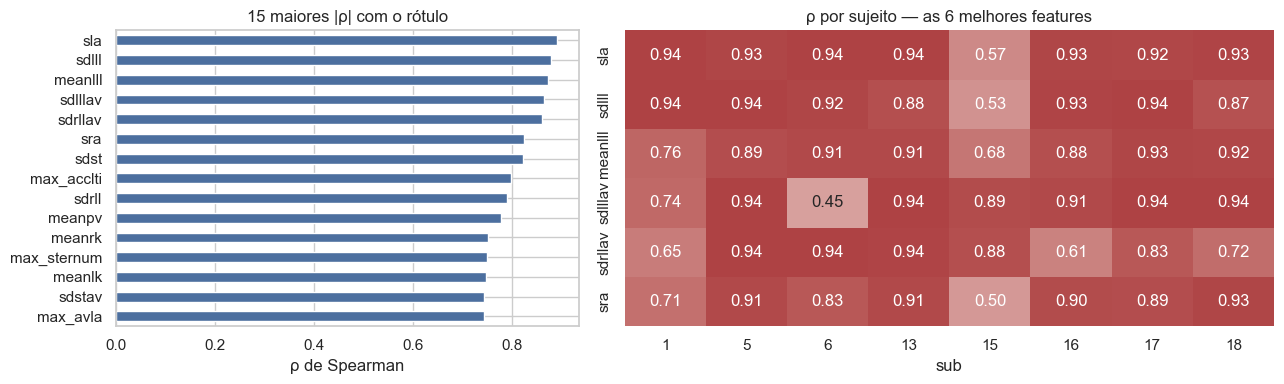

In [5]:
# (d) Poder preditivo individual (Spearman com o rótulo ordinal) e consistência entre sujeitos.
rho = X.corrwith(pd.Series(y), method="spearman").sort_values(key=abs, ascending=False)
top = list(rho.index[:6])

rho_suj = pd.DataFrame({s: X.loc[g == s, top].corrwith(pd.Series(y[g == s], index=X.index[g == s]),
                                                      method="spearman")
                        for s in np.unique(g)})
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 1.4]})
rho.head(15)[::-1].plot.barh(ax=axes[0], color="#4C6F9F")
axes[0].set(title="15 maiores |ρ| com o rótulo", xlabel="ρ de Spearman")
sns.heatmap(rho_suj, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1,
            cbar=False, ax=axes[1])
axes[1].set(title="ρ por sujeito — as 6 melhores features", xlabel="sub")
plt.tight_layout(); plt.show()

O que a exploração decide:

1. **Escala**: a z-score por sujeito está confirmada (média ≈ 0, dp = 1,000 em
   cada sujeito) e não há caudas pesadas (nenhuma feature com >1% de valores
   além de 5 dp). Mesmo assim, modelos sensíveis à escala (regressão logística,
   kNN, SVM) recebem um `StandardScaler` **dentro do pipeline**: ele reescala
   pelo treino agrupado, que não é o de cada sujeito.
2. **Redundância**: 13 pares com |ρ| > 0,95 e 96 com |ρ| > 0,8 — modelos
   lineares precisam de regularização; kNN sofre com dimensões redundantes.
3. **Poder preditivo e consistência**: 46 features têm |ρ| > 0,5 com o rótulo
   (18 acima de 0,7); as melhores (`sla`, `sdlll`, `meanlll`, `sdlllav`) chegam a
   ≈ 0,87–0,89, e o **sinal do efeito é o mesmo em todos os sujeitos**. Mas o
   mapa mostra exceções: `sub=15` tem correlações bem mais fracas (≈ 0,5–0,7) e
   `sub=6` tem `sdlllav` em 0,45. Vale guardar isso — reaparece na análise de erros.

## 4. Estratégia de validação

O fato central do problema, já visto no notebook 02: com um split aleatório uma
árvore sem limite chega a ≈ 1,00, e com sujeito novo cai para ≈ 0,74. Portanto:

- **Validação externa (estimativa final): leave-one-subject-out (LOSO)** — 8
  dobras; em cada uma, um corredor inteiro é o teste e só é tocado no fim.
- **Validação interna (escolha de hiperparâmetros): `GroupKFold(4)` por
  sujeito**, dentro dos 7 sujeitos de treino de cada dobra externa.
- **Validação aninhada**: a escolha dos hiperparâmetros nunca vê o sujeito de
  teste — evita o otimismo de escolher o melhor ponto olhando o teste.

In [6]:
externo = LeaveOneGroupOut()
interno = lambda: GroupKFold(n_splits=4)

for k, (tr, te) in enumerate(externo.split(X, y, g), 1):
    print(f"dobra {k}: teste = sub {g[te][0]:>2} ({len(te):>4} passadas) · "
          f"treino = {len(tr):>5} passadas, {len(np.unique(g[tr]))} sujeitos")

dobra 1: teste = sub  1 (1296 passadas) · treino = 11217 passadas, 7 sujeitos
dobra 2: teste = sub  5 (1683 passadas) · treino = 10830 passadas, 7 sujeitos
dobra 3: teste = sub  6 (1641 passadas) · treino = 10872 passadas, 7 sujeitos
dobra 4: teste = sub 13 (1761 passadas) · treino = 10752 passadas, 7 sujeitos
dobra 5: teste = sub 15 (1677 passadas) · treino = 10836 passadas, 7 sujeitos
dobra 6: teste = sub 16 (1410 passadas) · treino = 11103 passadas, 7 sujeitos
dobra 7: teste = sub 17 (1641 passadas) · treino = 10872 passadas, 7 sujeitos
dobra 8: teste = sub 18 (1404 passadas) · treino = 11109 passadas, 7 sujeitos


## 5. Pré-processamento em *pipelines*

Todo passo que **aprende** algo dos dados (mediana de imputação, média/dp do
escalonador) fica dentro do `Pipeline`, de modo que é reajustado só com o
treino de cada dobra. Fazer isso fora do pipeline é a fonte mais comum de
vazamento.

Cada candidato é: `SimpleImputer(mediana)` → `StandardScaler` (só onde a escala
importa) → classificador. A imputação é inócua aqui (não há ausentes em `X`),
mas protege o pipeline caso o dado mude.

In [7]:
def pipeline(clf, escala=True):
    passos = [("imp", SimpleImputer(strategy="median"))]
    if escala:
        passos.append(("esc", StandardScaler()))
    return Pipeline(passos + [("clf", clf)])


# (pipeline, grade de hiperparâmetros). Grades pequenas de propósito: o objetivo é um
# processo reprodutível e barato, não esgotar o espaço de busca.
CANDIDATOS = {
    "acaso (mais frequente)": (pipeline(DummyClassifier(strategy="most_frequent"), False), {}),
    "regressão logística": (
        pipeline(LogisticRegression(max_iter=2000, random_state=SEED)),
        {"clf__C": [0.01, 0.1, 1.0]}),
    "kNN": (
        pipeline(KNeighborsClassifier()),
        {"clf__n_neighbors": [15, 50]}),
    "SVM (RBF)": (
        pipeline(SVC(random_state=SEED)),
        {"clf__C": [1, 10]}),
    "árvore de decisão": (
        pipeline(DecisionTreeClassifier(random_state=SEED), False),
        {"clf__max_depth": [2, 3, 5, None], "clf__min_samples_leaf": [1, 20]}),
    "floresta aleatória": (
        pipeline(RandomForestClassifier(150, random_state=SEED, n_jobs=-1), False),
        {"clf__max_depth": [6, None], "clf__min_samples_leaf": [1, 5]}),
    "gradient boosting": (
        pipeline(HistGradientBoostingClassifier(max_iter=150, random_state=SEED), False),
        {"clf__max_depth": [3, None], "clf__learning_rate": [0.05, 0.1]}),
}
print(len(CANDIDATOS), "candidatos:", ", ".join(CANDIDATOS))

7 candidatos: acaso (mais frequente), regressão logística, kNN, SVM (RBF), árvore de decisão, floresta aleatória, gradient boosting


## 6. Comparação de algoritmos — validação aninhada

Para cada candidato e cada uma das 8 dobras externas: `GridSearchCV` (interno,
por sujeito, métrica F1-macro) escolhe os hiperparâmetros com 7 sujeitos, e o
modelo escolhido prevê o sujeito deixado de fora. As previsões
(rótulos **e** probabilidades, quando existem) são guardadas para toda a
análise posterior. Leva alguns minutos.

In [8]:
def avalia_aninhado(modelo, grade):
    pred = np.empty_like(y)
    proba = np.full((len(y), 3), np.nan)
    escolhas = []
    for tr, te in externo.split(X, y, g):
        if grade:
            busca = GridSearchCV(modelo, grade, cv=interno(), scoring="f1_macro", n_jobs=-1)
            busca.fit(X.iloc[tr], y[tr], groups=g[tr])
            melhor = busca.best_estimator_
            escolhas.append(busca.best_params_)
        else:
            melhor = modelo.fit(X.iloc[tr], y[tr])
            escolhas.append({})
        pred[te] = melhor.predict(X.iloc[te])
        if hasattr(melhor, "predict_proba"):
            proba[te] = melhor.predict_proba(X.iloc[te])
    return pred, proba, escolhas


RESULT = {}
for nome, (modelo, grade) in CANDIDATOS.items():
    t0 = time.time()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        pred, proba, escolhas = avalia_aninhado(modelo, grade)
    RESULT[nome] = {"pred": pred, "proba": proba, "escolhas": escolhas}
    print(f"{nome:24} acc = {accuracy_score(y, pred):.3f} · F1-macro = {f1_score(y, pred, average='macro'):.3f} "
          f"· {time.time() - t0:5.0f}s")

acaso (mais frequente)   acc = 0.333 · F1-macro = 0.167 ·     1s


regressão logística      acc = 0.724 · F1-macro = 0.727 ·     5s


kNN                      acc = 0.617 · F1-macro = 0.619 ·     4s


SVM (RBF)                acc = 0.808 · F1-macro = 0.811 ·     4s


árvore de decisão        acc = 0.876 · F1-macro = 0.877 ·    12s


floresta aleatória       acc = 0.877 · F1-macro = 0.878 ·    37s


gradient boosting        acc = 0.871 · F1-macro = 0.869 ·    45s


In [9]:
def metricas(pred):
    return {
        "acurácia": accuracy_score(y, pred),
        "acurácia balanceada": balanced_accuracy_score(y, pred),
        "F1-macro": f1_score(y, pred, average="macro"),
        "kappa quadrático": cohen_kappa_score(y, pred, weights="quadratic"),
        "erros extremos (none↔heavy)": int(((y == 0) & (pred == 2)).sum() + ((y == 2) & (pred == 0)).sum()),
    }


tabela = pd.DataFrame({n: metricas(r["pred"]) for n, r in RESULT.items()}).T
por_suj = pd.DataFrame({n: pd.Series(r["pred"] == y).groupby(g).mean() for n, r in RESULT.items()}).T
tabela["acc média/sujeito"] = por_suj.mean(axis=1)
tabela["dp entre sujeitos"] = por_suj.std(axis=1)
tabela["pior sujeito"] = por_suj.min(axis=1)
tabela = tabela.sort_values("F1-macro", ascending=False)
tabela.round(3)

,acurácia,acurácia balanceada,F1-macro,kappa quadrático,erros extremos (none↔heavy),acc média/sujeito,dp entre sujeitos,pior sujeito
floresta aleatória,0.877,0.877,0.878,0.901,32.0,0.878,0.124,0.703
árvore de decisão,0.876,0.876,0.877,0.846,336.0,0.877,0.092,0.710
gradient boosting,0.871,0.871,0.869,0.868,176.0,0.872,0.124,0.627
SVM (RBF),0.808,0.808,0.811,0.815,203.0,0.806,0.184,0.576
regressão logística,0.724,0.724,0.727,0.728,342.0,0.713,0.206,0.452
kNN,0.617,0.617,0.619,0.610,81.0,0.611,0.127,0.438
acaso (mais frequente),0.333,0.333,0.167,0.000,4171.0,0.333,0.000,0.333


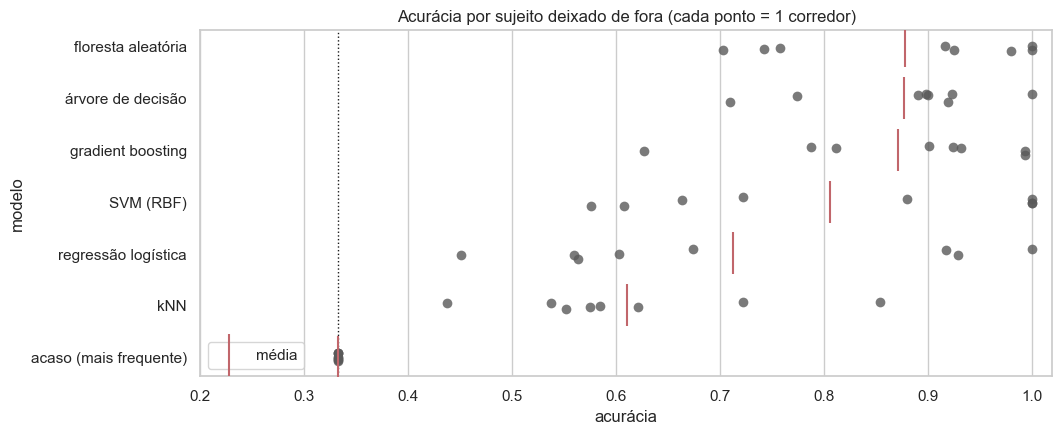

In [10]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ordem = list(tabela.index)
sns.stripplot(data=por_suj.loc[ordem].T.melt(var_name="modelo", value_name="acurácia"),
              x="acurácia", y="modelo", order=ordem, color="0.35", size=7, alpha=.8, ax=ax)
ax.scatter(tabela.loc[ordem, "acc média/sujeito"], range(len(ordem)), marker="|", s=900,
           color="#C1666B", zorder=5, label="média")
ax.axvline(1/3, ls=":", color="k", lw=1)
ax.set(title="Acurácia por sujeito deixado de fora (cada ponto = 1 corredor)", xlabel="acurácia", xlim=(0.2, 1.02))
ax.legend(loc="lower left"); plt.show()

A comparação é feita **por corredor**, não só pelo número agregado. Para
quantificar a incerteza, um *bootstrap por sujeito* (reamostrar os 8 corredores
com reposição, 2000 vezes):

In [11]:
rng = np.random.default_rng(SEED)
sujeitos = np.unique(g)
amostras = rng.choice(sujeitos, size=(2000, len(sujeitos)), replace=True)

def boot_f1(pred):
    f = {s: (y[g == s], pred[g == s]) for s in sujeitos}
    out = []
    for amostra in amostras:
        yy = np.concatenate([f[s][0] for s in amostra]); pp = np.concatenate([f[s][1] for s in amostra])
        out.append(f1_score(yy, pp, average="macro"))
    return np.array(out)

boot = {n: boot_f1(r["pred"]) for n, r in RESULT.items()}
ic = pd.DataFrame({n: {"F1-macro": f1_score(y, RESULT[n]["pred"], average="macro"),
                       "IC95% inf": np.percentile(b, 2.5), "IC95% sup": np.percentile(b, 97.5)}
                   for n, b in boot.items()}).T.loc[ordem]
ic.round(3)

,F1-macro,IC95% inf,IC95% sup
floresta aleatória,0.878,0.796,0.953
árvore de decisão,0.877,0.812,0.934
gradient boosting,0.869,0.771,0.945
SVM (RBF),0.811,0.691,0.924
regressão logística,0.727,0.590,0.863
kNN,0.619,0.538,0.705
acaso (mais frequente),0.167,0.167,0.167


**Leitura da comparação** (F1-macro, validação aninhada):

- Três modelos baseados em árvores formam o topo e são **estatisticamente
  indistinguíveis**: floresta (0,878), árvore única (0,877) e gradient boosting
  (0,869), com intervalos de 95 % que se sobrepõem quase totalmente
  (≈ 0,77–0,95). A escolha do "melhor" por F1-macro é, na prática, um empate.
- Os modelos de fronteira suave ficam atrás: SVM 0,81, regressão logística
  0,73, kNN 0,62 (este último, com muitas dimensões redundantes, é o pior).
- Todos superam muito o acaso (F1-macro 0,167).
- O ganho de algoritmo é pequeno perto do desvio **entre sujeitos** (0,09–0,21
  de desvio-padrão da acurácia): o que mais muda o resultado é *quem* está no
  teste, não qual algoritmo se usa.
- Onde a floresta se destaca é nos **erros extremos** `none↔heavy`: 32, contra
  336 da árvore única e 176 do gradient boosting. Para um alvo ordinal isso
  conta (kappa quadrático 0,90 contra 0,85 e 0,87).

## 7. Avaliação detalhada do melhor modelo

Escolhido pelo **F1-macro** da validação aninhada.

melhor por F1-macro: floresta aleatória
              precision    recall  f1-score   support

        none      1.000     0.967     0.983      4171
        mild      0.806     0.843     0.824      4171
       heavy      0.833     0.822     0.827      4171

    accuracy                          0.877     12513
   macro avg      0.880     0.877     0.878     12513
weighted avg      0.880     0.877     0.878     12513



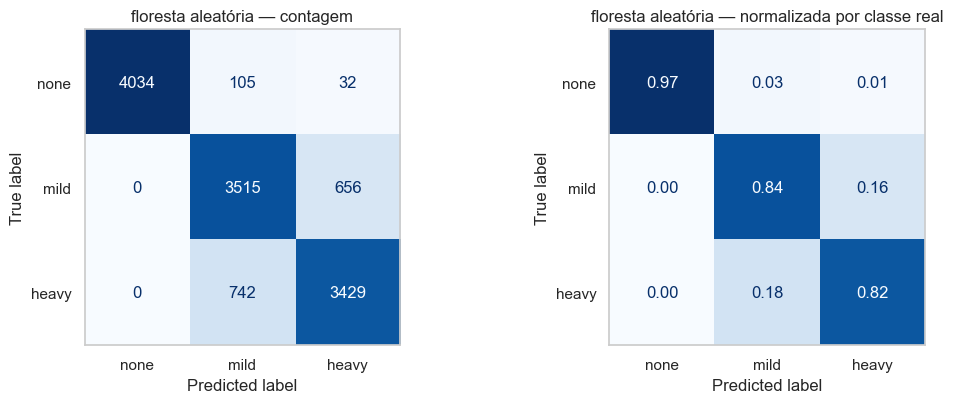

In [12]:
MELHOR = tabela.index[0]
print("melhor por F1-macro:", MELHOR)
pred_m, proba_m = RESULT[MELHOR]["pred"], RESULT[MELHOR]["proba"]

print(classification_report(y, pred_m, target_names=NOMES, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, norm, fmt, t in [(axes[0], None, "d", "contagem"), (axes[1], "true", ".2f", "normalizada por classe real")]:
    ConfusionMatrixDisplay(confusion_matrix(y, pred_m, normalize=norm), display_labels=NOMES).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=fmt)
    ax.set_title(f"{MELHOR} — {t}"); ax.grid(False)
plt.tight_layout(); plt.show()

## 8. Análise de erros

Um número agregado esconde **onde** e **para quem** o modelo falha. Quatro
perguntas:

1. Os erros são entre classes vizinhas (aceitável) ou extremas?
2. Que sujeitos concentram os erros?
3. Os erros ocorrem com baixa confiança (detectáveis) ou com alta (perigosos)?
4. Há um viés sistemático (sub ou superestimar a fadiga)?

In [13]:
dist = np.abs(pred_m - y)
print("distância ordinal do erro:", {f"|erro|={k}": f"{(dist == k).mean():.1%}" for k in (0, 1, 2)})
print("viés (previsto − real, média):", round(float((pred_m - y).mean()), 3),
      "→ >0: superestima fadiga; <0: subestima")

por_classe_suj = (pd.DataFrame({"sub": g, "real": [CLASSES[v] for v in y], "acerto": pred_m == y})
                  .pivot_table(index="sub", columns="real", values="acerto", aggfunc="mean")[NOMES])
display(por_classe_suj.round(3).assign(total=pd.Series(pred_m == y).groupby(g).mean().round(3)))

distância ordinal do erro: {'|erro|=0': '87.7%', '|erro|=1': '12.0%', '|erro|=2': '0.3%'}
viés (previsto − real, média): 0.007 → >0: superestima fadiga; <0: subestima


real,none,mild,heavy,total
sub,,,,
1,1.000,1.000,1.000,1.000
5,1.000,1.000,1.000,1.000
6,0.941,1.000,0.333,0.758
13,1.000,0.940,1.000,0.980
15,0.812,0.773,0.524,0.703
16,1.000,0.464,0.764,0.743
17,1.000,0.750,1.000,0.917
18,1.000,0.776,1.000,0.925


,acurácia,n
faixa de confiança,,
"(-0.001, 0.5]",0.570,1010
"(0.5, 0.7]",0.835,5589
"(0.7, 0.9]",0.963,4802
"(0.9, 1.0]",1.000,1112


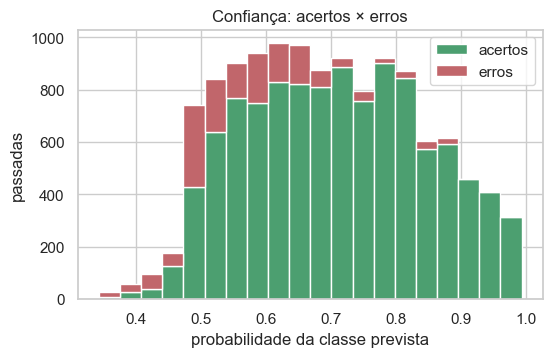

In [14]:
if not np.isnan(proba_m).any():
    conf = proba_m.max(axis=1)
    acerto = pred_m == y
    faixas = pd.cut(conf, [0, .5, .7, .9, 1.0], include_lowest=True)
    calib = (pd.DataFrame({"faixa de confiança": faixas, "acerto": acerto})
             .groupby("faixa de confiança", observed=True)["acerto"].agg(["mean", "size"])
             .rename(columns={"mean": "acurácia", "size": "n"}))
    display(calib.round(3))
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.hist([conf[acerto], conf[~acerto]], bins=20, stacked=True, color=["#4C9F70", "#C1666B"],
            label=["acertos", "erros"])
    ax.set(xlabel="probabilidade da classe prevista", ylabel="passadas", title="Confiança: acertos × erros")
    ax.legend(); plt.show()
else:
    print(f"{MELHOR} não produz probabilidades — análise de confiança omitida.")

**Respostas às quatro perguntas** (floresta aleatória, LOSO):

1. **Vizinhas ou extremas?** 87,7 % de acertos; 12,0 % dos erros são entre
   classes vizinhas; só **0,3 %** confundem `none` com `heavy`. Quase todo o
   erro está entre `mild` e `heavy`: `none` é detectada com precisão 1,000 e
   recall 0,967.
2. **Que sujeitos?** `sub` 1 e 5 são classificados sem erro. O erro se concentra
   em `sub=15` (acurácia 0,70), `sub=16` (0,74, em `mild`: 0,46) e `sub=6`
   (0,76, em `heavy`: 0,33). `sub=15` é o mesmo corredor cujas correlações
   individuais eram mais fracas na seção 3 — o modelo falha onde o sinal é
   mais fraco, o que sugere uma resposta à fadiga menos típica nesse corredor,
   não um defeito do algoritmo.
3. **Confiança.** A probabilidade da classe prevista é **informativa**:
   acurácia de 0,57 na faixa ≤ 0,5, 0,84 em 0,5–0,7, 0,96 em 0,7–0,9 e 1,00
   acima de 0,9. Dá para usar a probabilidade para "abster-se" em casos duvidosos.
4. **Viés.** Praticamente nulo (previsto − real = +0,007): o modelo não
   superestima nem subestima a fadiga sistematicamente.

## 9. Modelo final, persistência e inferência

O estimador de desempenho já foi obtido (seção 6). Para **uso**, o modelo
final é ajustado com os **8 sujeitos**, com os hiperparâmetros escolhidos pelo
mesmo `GridSearchCV` (agora sobre os 8 sujeitos). Em seguida salvamos o
pipeline completo (imputação + escala + classificador) e simulamos a inferência
em passadas novas — carregando o arquivo do disco, como em produção.

In [15]:
modelo, grade = CANDIDATOS[MELHOR]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    if grade:
        busca = GridSearchCV(modelo, grade, cv=interno(), scoring="f1_macro", n_jobs=-1).fit(X, y, groups=g)
        final, params = busca.best_estimator_, busca.best_params_
    else:
        final, params = modelo.fit(X, y), {}
print("hiperparâmetros finais:", params)

destino = Path("data/models"); destino.mkdir(parents=True, exist_ok=True)
caminho = destino / "fadiga_classificador.joblib"
joblib.dump({"pipeline": final, "features": FEATURES, "classes": CLASSES,
             "modelo": MELHOR, "params": params,
             "desempenho_loso_f1_macro": float(tabela.loc[MELHOR, "F1-macro"])}, caminho)
print(f"salvo em {caminho} ({caminho.stat().st_size / 1e6:.1f} MB)")

hiperparâmetros finais: {'clf__max_depth': None, 'clf__min_samples_leaf': 1}
salvo em data/models/fadiga_classificador.joblib (0.8 MB)


In [16]:
def prever_fadiga(df, caminho=caminho):
    # Carrega o artefato e classifica passadas. `df` precisa ter as colunas de FEATURES já
    # normalizadas por sujeito, como na TableFeats.
    art = joblib.load(caminho)
    faltam = [c for c in art["features"] if c not in df.columns]
    if faltam:
        raise ValueError(f"{len(faltam)} features ausentes, ex.: {faltam[:3]}")
    Xn = df[art["features"]]
    out = pd.DataFrame({"previsto": [art["classes"][k] for k in art["pipeline"].predict(Xn)]}, index=df.index)
    if hasattr(art["pipeline"], "predict_proba"):
        P = art["pipeline"].predict_proba(Xn)
        for k, nome in art["classes"].items():
            out[f"P({nome})"] = P[:, k]
    return out


# Demonstração: 6 passadas aleatórias. ATENÇÃO — todos os sujeitos estão no treino do modelo
# final, então isto demonstra a *mecânica* da inferência, não o desempenho (esse é o da seção 6).
amostra = feats.sample(6, random_state=SEED)
pd.concat([amostra[["sub"]], amostra["fatigue"].map(CLASSES).rename("real"), prever_fadiga(amostra)], axis=1).round(3)

,sub,real,previsto,P(none),P(mild),P(heavy)
10487,17,mild,mild,0.0,1.0,0.0
6686,15,none,none,1.0,0.0,0.0
1593,5,none,none,1.0,0.0,0.0
1570,5,none,none,1.0,0.0,0.0
1665,5,none,none,1.0,0.0,0.0
5998,13,heavy,heavy,0.0,0.0,1.0


## 10. Conclusões e limitações

**O processo, em resumo.** Problema ordinal de 3 classes → auditoria com
asserções → EDA que informa a modelagem → validação por sujeito aninhada →
pipelines sem vazamento → 7 algoritmos comparados com incerteza por bootstrap
de sujeitos → análise de erros → modelo final persistido e carregável.

**Resultado.** A floresta aleatória (F1-macro ≈ 0,88; acurácia 0,877) é o
melhor modelo por um fio: empata com a árvore única e com o gradient boosting
dentro da incerteza. Ela é preferível por produzir **muito menos erros
extremos** (32 contra 336) e probabilidades calibráveis na prática; a árvore
única é a alternativa quando a interpretabilidade pesa mais (notebook 02). O
modelo salvo está em `data/models/fadiga_classificador.joblib`.

**Limitações**

1. **Normalização transdutiva** (já apontada nos notebooks 01 e 02): as
   features foram z-scoradas com a distribuição de cada sujeito *nas três
   condições*. O desempenho acima vale para um corredor cuja linha de base
   foi calibrada, não para um corredor totalmente novo e não visto. O modelo
   final **exige entrada normalizada do mesmo modo** — a função
   `prever_fadiga` não faz essa normalização.
2. **Só 8 corredores.** Os IC95 % do F1-macro têm ≈ 15 pontos de largura;
   diferenças de 1–2 pontos entre modelos não significam nada.
3. **Passadas do mesmo corredor não são independentes**; por isso todo o
   pareamento treino/teste é por sujeito. O bootstrap por sujeito respeita isso,
   mas com apenas 8 unidades é um intervalo aproximado.
4. **Hiperparâmetros**: as grades são pequenas de propósito; a floresta com
   `max_depth=None` e `min_samples_leaf=1` ajusta o treino perfeitamente — por
   isso, na demonstração da seção 9, as probabilidades saem 0/1 em dados que o
   modelo já viu. Isso **não** reflete a confiança em dados novos (seção 8:
   acima de 0,9 só 9 % das passadas).
5. As classes são derivadas de **voltas** do protocolo, não de uma medida
   contínua de fadiga; o rótulo `mild` mistura corredores em estados
   fisiológicos diferentes, o que explica parte da confusão `mild↔heavy`.

**Próximos passos:** (a) refazer o pipeline com features por janela do sinal
bruto e normalização apenas com estatísticas do treino ou da linha de base
`none` do próprio corredor (remove a transdução); (b) tratar o alvo como
ordinal (regressão ou classificação ordinal); (c) limiar de abstenção pela
confiança; (d) mais sujeitos — sem isso, nenhuma conclusão de ranking de
algoritmos é firme.